# Master Results Dashboard - 4 Cancer Types x 4 Architectures

Run this notebook **after** finishing the four training notebooks.
It reads every `Results/*/comparison.csv` and merges them into a single report:

- `Results/master_comparison.csv` - 16 rows (4 cancer types x 4 architectures)
- `Results/master_summary.xlsx` - full table, best model per cancer, pivots
- `Results/figures/master_heatmap.png` - F1 heatmap
- `Results/master_table.md` - Markdown table ready to paste into the project book


In [9]:


import os, json, glob
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

RESULTS_ROOT = f'Results'
os.makedirs(f'{RESULTS_ROOT}/figures', exist_ok=True)

CANCERS = ['colon', 'lung', 'leukemia', 'skin']
frames = []
for c in CANCERS:
    p = f'{RESULTS_ROOT}/{c}/comparison.csv'
    if os.path.exists(p):
        frames.append(pd.read_csv(p))
    else:
        print(f'No results yet for {c} ({p})')

assert frames, 'No result files found - run the training notebooks first'
master = pd.concat(frames, ignore_index=True)
print(f'{master["cancer_type"].nunique()} cancer types | {len(master)} models')
master.head()

4 cancer types | 16 models


,cancer_type,model,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,auc,...,f1__Benign,recall__Benign,f1__Malignant_Pre-B,recall__Malignant_Pre-B,f1__Malignant_Pro-B,recall__Malignant_Pro-B,f1__Malignant_early Pre-B,recall__Malignant_early Pre-B,f1__Malignant,recall__Malignant
0,colon,ResNet50,0.9995,0.9995,0.9995,0.9995,0.9995,0.9995,0.9995,1.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,colon,VGG19,0.9965,0.9965,0.9965,0.9965,0.9965,0.9965,0.9965,0.9999,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,colon,MobileNet,0.9740,0.9748,0.9740,0.9740,0.9748,0.9740,0.9740,0.9991,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,colon,CNN,0.5000,0.2500,0.5000,0.3333,0.2500,0.5000,0.3333,0.5000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,lung,VGG19,0.9890,0.9890,0.9890,0.9890,0.9890,0.9890,0.9890,0.9992,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Full table

In [10]:
cols = ['cancer_type', 'model', 'accuracy', 'precision_macro', 'recall_macro',
        'f1_macro', 'auc', 'train_time_sec', 'total_params', 'epochs']
table = master[cols].sort_values(['cancer_type', 'f1_macro'], ascending=[True, False])
display(table.style.format({'accuracy': '{:.4f}', 'f1_macro': '{:.4f}',
                            'auc': '{:.4f}', 'train_time_sec': '{:.0f}'})
             .background_gradient(subset=['f1_macro'], cmap='Greens'))

,cancer_type,model,accuracy,precision_macro,recall_macro,f1_macro,auc,train_time_sec,total_params,epochs
0,colon,ResNet50,0.9995,0.999500,0.999500,0.9995,1.0000,182,24146946,5
1,colon,VGG19,0.9965,0.996500,0.996500,0.9965,0.9999,483,20190402,5
2,colon,MobileNet,0.9740,0.974800,0.974000,0.9740,0.9991,68,3525954,3
3,colon,CNN,0.5000,0.250000,0.500000,0.3333,0.5000,119,33684162,5
8,leukemia,ResNet50,0.9980,0.998000,0.997700,0.9979,1.0000,255,90861828,5
9,leukemia,VGG19,0.9877,0.985600,0.986700,0.9861,0.9999,465,36966852,5
10,leukemia,MobileNet,0.9693,0.966800,0.964900,0.9658,0.9983,104,3526212,5
11,leukemia,CNN,0.5988,0.810400,0.660800,0.5616,0.9747,764,33684420,5
4,lung,VGG19,0.9890,0.989000,0.989000,0.9890,0.9992,780,20190531,5
5,lung,ResNet50,0.9833,0.983500,0.983300,0.9833,0.9992,290,24147075,5


## Best model per cancer type

,cancer_type,model,accuracy,precision_macro,recall_macro,f1_macro,auc,train_time_sec,total_params,epochs
0,colon,ResNet50,0.9995,0.9995,0.9995,0.9995,1.0000,182.4,24146946,5
1,leukemia,ResNet50,0.9980,0.9980,0.9977,0.9979,1.0000,254.6,90861828,5
2,lung,VGG19,0.9890,0.9890,0.9890,0.9890,0.9992,779.5,20190531,5
3,skin,ResNet50,0.9519,0.9540,0.9503,0.9516,0.9882,2042.4,90861570,15


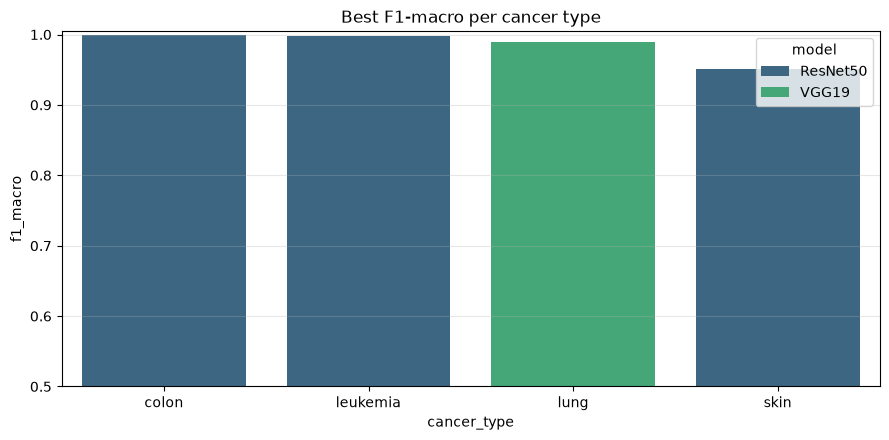

In [11]:
best = (master.sort_values('f1_macro', ascending=False)
              .groupby('cancer_type', as_index=False).first())
display(best[cols])

plt.figure(figsize=(9, 4.5))
sns.barplot(data=best, x='cancer_type', y='f1_macro', hue='model', dodge=False, palette='viridis')
plt.ylim(min(0.5, best['f1_macro'].min() - 0.05), 1.005)
plt.title('Best F1-macro per cancer type'); plt.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.savefig(f'{RESULTS_ROOT}/figures/master_best_per_cancer.png', dpi=120)
plt.show()

## Heatmap: F1-macro per architecture and cancer type

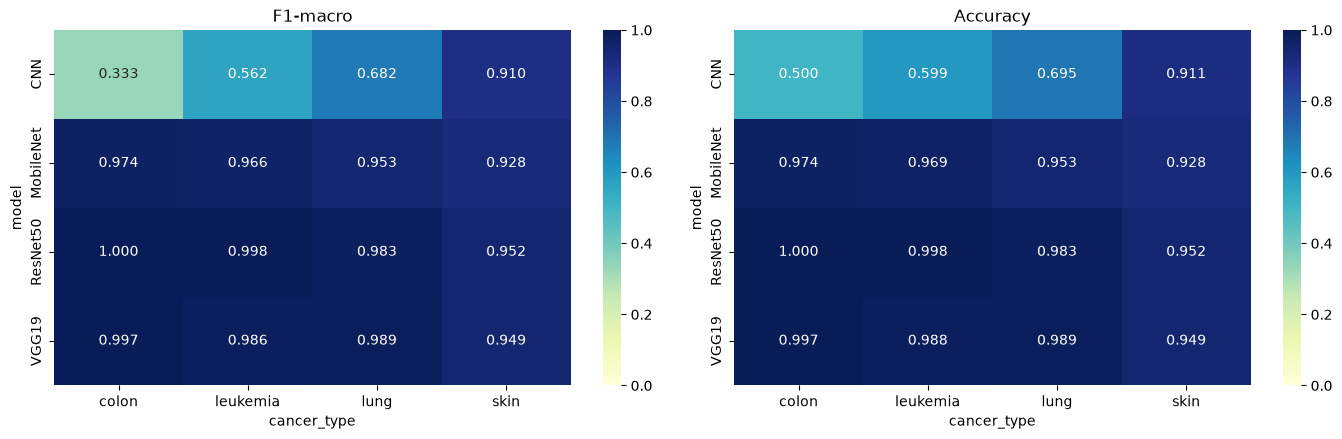


Average performance per architecture across all four cancer types:


,accuracy,f1_macro,auc,train_time_sec
model,,,,
ResNet50,0.9832,0.9831,0.9968,692.300
VGG19,0.9805,0.9800,0.9968,1523.025
MobileNet,0.9561,0.9551,0.9916,241.775
CNN,0.6763,0.6218,0.8456,731.025


In [12]:
pivot_f1 = master.pivot_table(index='model', columns='cancer_type', values='f1_macro')
pivot_acc = master.pivot_table(index='model', columns='cancer_type', values='accuracy')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(pivot_f1, annot=True, fmt='.3f', cmap='YlGnBu', vmin=0, vmax=1, ax=ax[0])
ax[0].set_title('F1-macro')
sns.heatmap(pivot_acc, annot=True, fmt='.3f', cmap='YlGnBu', vmin=0, vmax=1, ax=ax[1])
ax[1].set_title('Accuracy')
plt.tight_layout(); plt.savefig(f'{RESULTS_ROOT}/figures/master_heatmap.png', dpi=120)
plt.show()

print('\nAverage performance per architecture across all four cancer types:')
display(master.groupby('model')[['accuracy', 'f1_macro', 'auc', 'train_time_sec']]
              .mean().round(4).sort_values('f1_macro', ascending=False))

## Export to external files

In [13]:
master_path = f'{RESULTS_ROOT}/master_comparison.csv'
master.to_csv(master_path, index=False)

with pd.ExcelWriter(f'{RESULTS_ROOT}/master_summary.xlsx', engine='openpyxl') as xl:
    master.to_excel(xl, sheet_name='all_models', index=False)
    best.to_excel(xl, sheet_name='best_per_cancer', index=False)
    pivot_f1.to_excel(xl, sheet_name='f1_pivot')
    pivot_acc.to_excel(xl, sheet_name='accuracy_pivot')
    (master.groupby('model')[['accuracy', 'f1_macro', 'auc', 'train_time_sec']]
           .mean().round(4).to_excel(xl, sheet_name='avg_by_architecture'))

print('Saved:')
print(' -', master_path)
print(' -', f'{RESULTS_ROOT}/master_summary.xlsx')
print(' -', f'{RESULTS_ROOT}/figures/master_heatmap.png')

Saved:
 - Results/master_comparison.csv
 - Results/master_summary.xlsx
 - Results/figures/master_heatmap.png


## Markdown table for the project book

In [14]:
lines = ['| Cancer | Architecture | Accuracy | Precision | Recall | F1 | AUC |',
         '|---|---|---|---|---|---|---|']
for _, r in table.iterrows():
    auc = f"{r['auc']:.4f}" if pd.notna(r['auc']) else '-'
    lines.append(f"| {r['cancer_type']} | {r['model']} | {r['accuracy']:.4f} | "
                 f"{r['precision_macro']:.4f} | {r['recall_macro']:.4f} | "
                 f"{r['f1_macro']:.4f} | {auc} |")
md_table = '\n'.join(lines)
with open(f'{RESULTS_ROOT}/master_table.md', 'w') as fh:
    fh.write(md_table)
print(md_table)

| Cancer | Architecture | Accuracy | Precision | Recall | F1 | AUC |
|---|---|---|---|---|---|---|
| colon | ResNet50 | 0.9995 | 0.9995 | 0.9995 | 0.9995 | 1.0000 |
| colon | VGG19 | 0.9965 | 0.9965 | 0.9965 | 0.9965 | 0.9999 |
| colon | MobileNet | 0.9740 | 0.9748 | 0.9740 | 0.9740 | 0.9991 |
| colon | CNN | 0.5000 | 0.2500 | 0.5000 | 0.3333 | 0.5000 |
| leukemia | ResNet50 | 0.9980 | 0.9980 | 0.9977 | 0.9979 | 1.0000 |
| leukemia | VGG19 | 0.9877 | 0.9856 | 0.9867 | 0.9861 | 0.9999 |
| leukemia | MobileNet | 0.9693 | 0.9668 | 0.9649 | 0.9658 | 0.9983 |
| leukemia | CNN | 0.5988 | 0.8104 | 0.6608 | 0.5616 | 0.9747 |
| lung | VGG19 | 0.9890 | 0.9890 | 0.9890 | 0.9890 | 0.9992 |
| lung | ResNet50 | 0.9833 | 0.9835 | 0.9833 | 0.9833 | 0.9992 |
| lung | MobileNet | 0.9530 | 0.9550 | 0.9530 | 0.9529 | 0.9953 |
| lung | CNN | 0.6950 | 0.7787 | 0.6950 | 0.6822 | 0.9324 |
| skin | ResNet50 | 0.9519 | 0.9540 | 0.9503 | 0.9516 | 0.9882 |
| skin | VGG19 | 0.9488 | 0.9485 | 0.9488 | 0.9486 | 0.98